# Quantum Mechanics — Chapter Visualizations
**PSE Lab | SeoulTech**

This notebook provides **7 visualizations** for the four chapters of the auxiliary notes (after D. Tong, *Lectures on Quantum Mechanics*), companion to the main Griffiths course.

| # | Visualization | Aux chapter | Griffiths |
|---|---|---|---|
| 1 | Wavefunction & Born Rule | Ch 1 | §1.2 |
| 2 | Double Slit Interference | Ch 1 | §1.2 |
| 3 | Infinite Well & Harmonic Oscillator Eigenstates | Ch 2 | §2.2–2.3 |
| 4 | Gaussian Wavepacket Spreading | Ch 2 | §2.4 |
| 5 | Tunnelling Through a Barrier | Ch 2 | §2.6 |
| 6 | Hydrogen Atom Orbitals | Ch 4 | §4.2 |
| 7 | Heisenberg Uncertainty: Position–Momentum | Ch 3 | §3.5 |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import FancyArrowPatch
from scipy.special import hermite, factorial, sph_harm_y, assoc_laguerre
from scipy.fft import fft, fftshift, fftfreq
import warnings
warnings.filterwarnings('ignore')
trapz = getattr(np, 'trapezoid', None) or np.trapz   # NumPy 2.x name

# ── Consistent dark style ──────────────────────────────────────────────────
plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor':   '#161b22',
    'axes.edgecolor':   '#30363d',
    'axes.labelcolor':  '#e6edf3',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'text.color':       '#e6edf3',
    'grid.color':       '#21262d',
    'grid.linestyle':   '--',
    'legend.facecolor': '#161b22',
    'legend.edgecolor': '#30363d',
    'font.size':        11,
})
COLORS = {'cyan': '#58a6ff', 'yellow': '#f0c040', 'green': '#3fb950',
          'red': '#f85149', 'purple': '#bc8cff', 'orange': '#ffa657'}
print('Setup complete.')

Setup complete.


## 1 · Wavefunction & Born Rule (Ch 1)
Visualize a Gaussian wavefunction $\psi(x)$, its probability density $|\psi|^2$, and the complex phase.

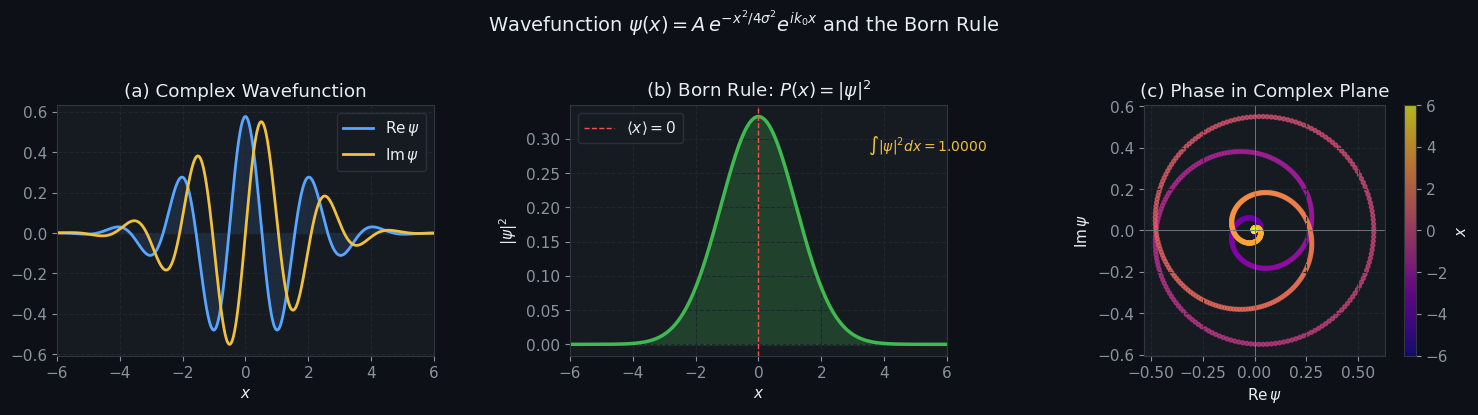

Normalization check: ∫|ψ|²dx = 1.000000


In [2]:
x = np.linspace(-6, 6, 1000)
sigma, k0 = 1.2, 3.0
psi = np.exp(-x**2 / (4*sigma**2)) * np.exp(1j*k0*x)
psi /= np.sqrt(trapz(np.abs(psi)**2, x))   # normalize

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle(r'Wavefunction $\psi(x) = A\,e^{-x^2/4\sigma^2}e^{ik_0 x}$ and the Born Rule',
             fontsize=14, y=1.02)

# (a) Re and Im
ax = axes[0]
ax.plot(x, psi.real, color=COLORS['cyan'],   lw=2, label=r'$\mathrm{Re}\,\psi$')
ax.plot(x, psi.imag, color=COLORS['yellow'], lw=2, label=r'$\mathrm{Im}\,\psi$')
ax.fill_between(x, psi.real, alpha=0.12, color=COLORS['cyan'])
ax.set_xlabel('$x$'); ax.set_title('(a) Complex Wavefunction')
ax.legend(); ax.grid(True); ax.set_xlim(-6, 6)

# (b) Probability density
ax = axes[1]
prob = np.abs(psi)**2
ax.plot(x, prob, color=COLORS['green'], lw=2.5)
ax.fill_between(x, prob, alpha=0.25, color=COLORS['green'])
ax.axvline(0, color=COLORS['red'], ls='--', lw=1, label=r'$\langle x\rangle=0$')
ax.set_xlabel('$x$'); ax.set_ylabel(r'$|\psi|^2$')
ax.set_title(r'(b) Born Rule: $P(x)=|\psi|^2$')
ax.legend(); ax.grid(True); ax.set_xlim(-6, 6)

# annotation: normalization
norm_val = trapz(prob, x)
ax.text(3.5, max(prob)*0.85, fr'$\int|\psi|^2dx={norm_val:.4f}$',
        fontsize=10, color=COLORS['yellow'])

# (c) Phase plot in complex plane (first 200 points)
ax = axes[2]
sc = ax.scatter(psi.real, psi.imag, c=x, cmap='plasma', s=8, alpha=0.7)
plt.colorbar(sc, ax=ax, label='$x$')
ax.set_xlabel(r'$\mathrm{Re}\,\psi$'); ax.set_ylabel(r'$\mathrm{Im}\,\psi$')
ax.set_title('(c) Phase in Complex Plane')
ax.set_aspect('equal'); ax.grid(True)
ax.axhline(0, color='#8b949e', lw=0.5); ax.axvline(0, color='#8b949e', lw=0.5)

plt.tight_layout()
plt.savefig('qm_viz1_born_rule.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Normalization check: ∫|ψ|²dx = {norm_val:.6f}')

## 2 · Double Slit Interference (Ch 1)
Compare classical ($P_{12}=P_1+P_2$) vs quantum ($P_{12}=|\psi_1+\psi_2|^2$) intensities.

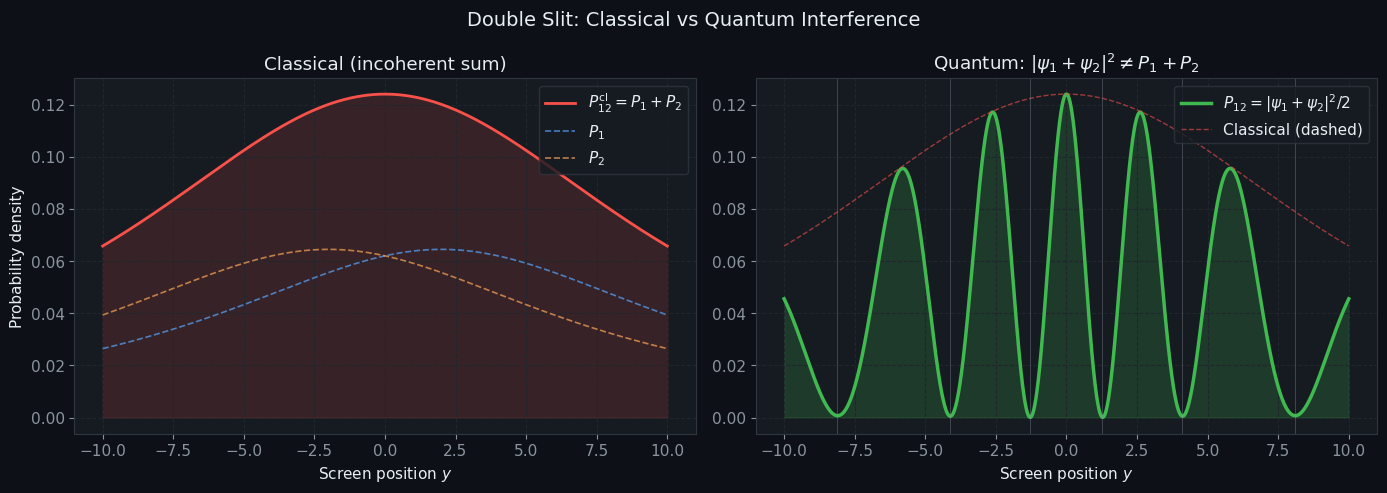

In [3]:
y  = np.linspace(-10, 10, 2000)   # screen position
d  = 2.0    # slit separation (half)
lam = 1.0   # de Broglie wavelength
L  = 10.0   # distance to screen

r1 = np.sqrt(L**2 + (y - d)**2)
r2 = np.sqrt(L**2 + (y + d)**2)

psi1 = np.exp(1j * 2*np.pi * r1 / lam) / r1
psi2 = np.exp(1j * 2*np.pi * r2 / lam) / r2
psi1 /= np.sqrt(trapz(np.abs(psi1)**2, y))
psi2 /= np.sqrt(trapz(np.abs(psi2)**2, y))

P1    = np.abs(psi1)**2
P2    = np.abs(psi2)**2
P_cl  = P1 + P2                          # classical: just add
P_qm  = np.abs(psi1 + psi2)**2 / 2      # quantum: interfere then square

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Double Slit: Classical vs Quantum Interference', fontsize=14)

ax = axes[0]
ax.plot(y, P_cl, color=COLORS['red'],  lw=2, label=r'$P_{12}^\mathrm{cl}=P_1+P_2$')
ax.plot(y, P1,   color=COLORS['cyan'], lw=1.2, ls='--', alpha=0.7, label='$P_1$')
ax.plot(y, P2,   color=COLORS['orange'], lw=1.2, ls='--', alpha=0.7, label='$P_2$')
ax.fill_between(y, P_cl, alpha=0.15, color=COLORS['red'])
ax.set_xlabel('Screen position $y$'); ax.set_ylabel('Probability density')
ax.set_title('Classical (incoherent sum)')
ax.legend(); ax.grid(True)

ax = axes[1]
ax.plot(y, P_qm, color=COLORS['green'], lw=2.5,
        label=r'$P_{12}=|\psi_1+\psi_2|^2/2$')
ax.plot(y, P_cl, color=COLORS['red'], lw=1, ls='--', alpha=0.6,
        label='Classical (dashed)')
ax.fill_between(y, P_qm, alpha=0.2, color=COLORS['green'])
# mark destructive nodes
nodes = y[np.where(np.diff(np.sign(np.gradient(P_qm))) > 0)]
for yn in nodes[:8]:
    ax.axvline(yn, color='#8b949e', lw=0.5, alpha=0.5)
ax.set_xlabel('Screen position $y$')
ax.set_title(r'Quantum: $|\psi_1+\psi_2|^2 \neq P_1+P_2$')
ax.legend(); ax.grid(True)

plt.tight_layout()
plt.savefig('qm_viz2_double_slit.png', dpi=150, bbox_inches='tight')
plt.show()

## 3 · Infinite Well & Harmonic Oscillator Eigenstates (Ch 2)
Show the first 5 energy eigenstates $\psi_n(x)$ and $|\psi_n|^2$ for both potentials.

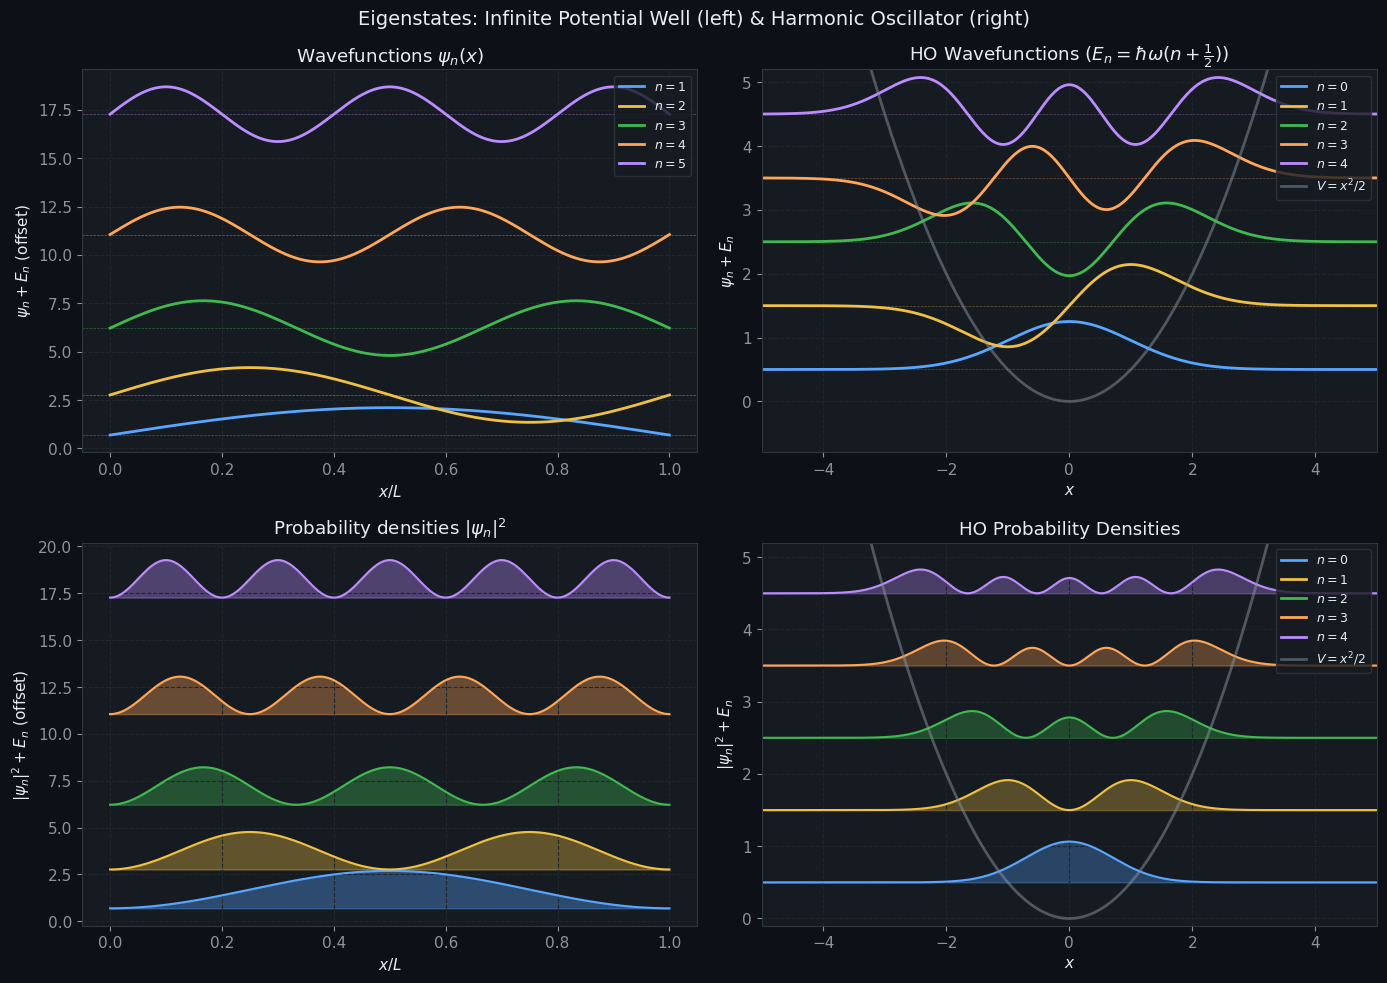

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Eigenstates: Infinite Potential Well (left) & Harmonic Oscillator (right)',
             fontsize=14)

# ── Infinite well ──────────────────────────────────────────────────────────
L = 1.0
x_well = np.linspace(0, L, 500)
palette = [COLORS['cyan'], COLORS['yellow'], COLORS['green'],
           COLORS['orange'], COLORS['purple']]

ax = axes[0, 0]
for n in range(1, 6):
    psi_n = np.sqrt(2/L) * np.sin(n*np.pi*x_well/L)
    En = n**2 * np.pi**2  # units ℏ²/2mL²
    offset = En * 0.07    # vertical offset for clarity
    ax.plot(x_well, psi_n + offset, color=palette[n-1], lw=2, label=f'$n={n}$')
    ax.axhline(offset, color=palette[n-1], lw=0.5, ls='--', alpha=0.5)
ax.set_xlabel('$x/L$'); ax.set_ylabel(r'$\psi_n + E_n$ (offset)')
ax.set_title(r'Wavefunctions $\psi_n(x)$')
ax.legend(fontsize=9); ax.grid(True)

ax = axes[1, 0]
for n in range(1, 6):
    psi_n = np.sqrt(2/L) * np.sin(n*np.pi*x_well/L)
    En = n**2 * np.pi**2
    ax.fill_between(x_well, np.abs(psi_n)**2 + En*0.07,
                    En*0.07, alpha=0.35, color=palette[n-1])
    ax.plot(x_well, np.abs(psi_n)**2 + En*0.07, color=palette[n-1], lw=1.5)
ax.set_xlabel('$x/L$'); ax.set_ylabel(r'$|\psi_n|^2 + E_n$ (offset)')
ax.set_title(r'Probability densities $|\psi_n|^2$')
ax.grid(True)

# ── Harmonic oscillator ────────────────────────────────────────────────────
x_ho = np.linspace(-5, 5, 1000)

def ho_wavefunction(n, x):
    Hn = hermite(n)
    Nn = 1.0 / np.sqrt(2**n * factorial(n) * np.sqrt(np.pi))
    return Nn * Hn(x) * np.exp(-x**2 / 2)

ax = axes[0, 1]
for n in range(5):
    psi_n = ho_wavefunction(n, x_ho)
    En = n + 0.5
    ax.plot(x_ho, psi_n + En, color=palette[n], lw=2, label=f'$n={n}$')
    ax.axhline(En, color=palette[n], lw=0.5, ls='--', alpha=0.4)

# draw parabola V(x) = x²/2
V = x_ho**2 / 2
ax.plot(x_ho, V, color='#8b949e', lw=2, ls='-', alpha=0.5, label='$V=x^2/2$')
ax.set_xlim(-5, 5); ax.set_ylim(-0.8, 5.2)   # clip parabola at top
ax.set_xlabel('$x$'); ax.set_ylabel(r'$\psi_n + E_n$')
ax.set_title(r'HO Wavefunctions ($E_n=\hbar\omega(n+\frac{1}{2})$)')
ax.legend(fontsize=9, loc='upper right'); ax.grid(True)

ax = axes[1, 1]
for n in range(5):
    psi_n = ho_wavefunction(n, x_ho)
    En = n + 0.5
    p = np.abs(psi_n)**2
    ax.fill_between(x_ho, p + En, En, alpha=0.3, color=palette[n])
    ax.plot(x_ho, p + En, color=palette[n], lw=1.5)
ax.plot(x_ho, V, color='#8b949e', lw=2, ls='-', alpha=0.5, label='$V=x^2/2$')
ax.set_xlim(-5, 5); ax.set_ylim(-0.1, 5.2)   # clip parabola at top
ax.set_xlabel('$x$'); ax.set_ylabel(r'$|\psi_n|^2 + E_n$')
ax.set_title(r'HO Probability Densities')
# add legend entries for each n
handles = [plt.Line2D([0],[0], color=palette[n], lw=2, label=f'$n={n}$') for n in range(5)]
handles.append(plt.Line2D([0],[0], color='#8b949e', lw=2, ls='-', alpha=0.5, label='$V=x^2/2$'))
ax.legend(handles=handles, fontsize=9, loc='upper right')
ax.grid(True)

plt.tight_layout()
plt.savefig('qm_viz3_eigenstates.png', dpi=150, bbox_inches='tight')
plt.show()

## 4 · Gaussian Wavepacket Spreading (Ch 2)
Animate how a free-particle Gaussian wavepacket travels at group velocity $v_g = \hbar k_0/m$ and spreads as $\Delta x \sim \sqrt{t}$.

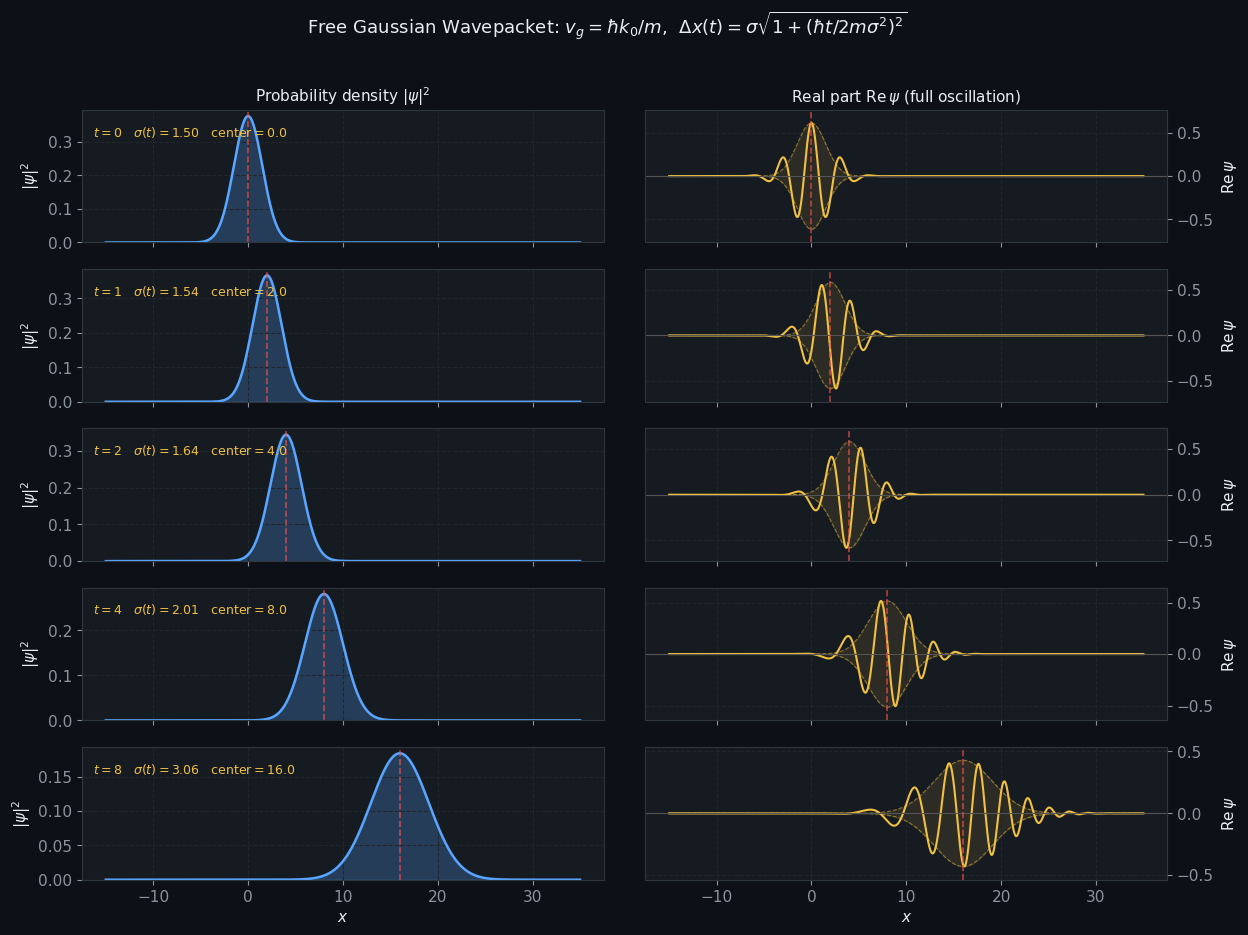

Width vs time:
  t=0: Dx = 1.500
  t=1: Dx = 1.537
  t=2: Dx = 1.641
  t=4: Dx = 2.007
  t=8: Dx = 3.060


In [5]:
# ── Parameters (ℏ = m = 1 units) ──────────────────────────────────────────
x   = np.linspace(-15, 35, 2000)
k0  = 2.0    # central wavevector
sig = 1.5    # initial width
times = [0, 1, 2, 4, 8]

def wavepacket(x, t, k0, sig):
    """Exact free-particle Gaussian propagation (hbar=m=1)."""
    width = sig**2 + 1j*t/2
    psi   = (sig**2 / (np.pi * width**2))**0.25 * \
            np.exp(-(x - k0*t)**2 / (4*width)) * \
            np.exp(1j*k0*x - 1j*k0**2*t/2)
    return psi

# Two sub-columns per time step:
#   left  = |psi|^2  (probability density)
#   right = Re psi   (full oscillation including negative values)
n_times = len(times)
fig, axes = plt.subplots(n_times, 2, figsize=(14, 10),
                         gridspec_kw={'width_ratios': [1, 1], 'wspace': 0.08},
                         sharex=True)
fig.suptitle(
    r'Free Gaussian Wavepacket: $v_g=\hbar k_0/m$,  '
    r'$\Delta x(t)=\sigma\sqrt{1+(\hbar t/2m\sigma^2)^2}$',
    fontsize=13)

# Column headers (top row only)
axes[0, 0].set_title(r'Probability density $|\psi|^2$', fontsize=11, pad=6)
axes[0, 1].set_title(r'Real part $\mathrm{Re}\,\psi$ (full oscillation)', fontsize=11, pad=6)

dx_analytic = []
for i, t in enumerate(times):
    psi_t   = wavepacket(x, t, k0, sig)
    P       = np.abs(psi_t)**2
    Re_psi  = psi_t.real
    sigma_t = sig * np.sqrt(1 + (t / (2*sig**2))**2)
    dx_analytic.append(sigma_t)
    center  = k0 * t
    info    = fr'$t={t}$   $\sigma(t)={sigma_t:.2f}$   center$={center:.1f}$'

    # ── Left panel: |psi|^2 ────────────────────────────────────────────
    ax0 = axes[i, 0]
    ax0.fill_between(x, P, alpha=0.25, color=COLORS['cyan'])
    ax0.plot(x, P, color=COLORS['cyan'], lw=1.8)
    ax0.axvline(center, color=COLORS['red'], lw=1.2, ls='--', alpha=0.7)
    ax0.text(0.02, 0.80, info, transform=ax0.transAxes,
             fontsize=9, color=COLORS['yellow'])
    ax0.set_ylabel(r'$|\psi|^2$')
    ax0.set_ylim(bottom=0)
    ax0.grid(True)

    # ── Right panel: Re psi  (symmetric y-axis — shows full oscillation)
    ax1 = axes[i, 1]
    amp = np.max(np.abs(Re_psi))   # peak amplitude
    # Gaussian envelope +/-
    env = amp * np.exp(-(x - center)**2 / (2 * sigma_t**2))
    ax1.fill_between(x,  env, -env, alpha=0.10, color=COLORS['yellow'])
    ax1.plot(x,  env, color=COLORS['yellow'], lw=0.8, ls='--', alpha=0.5)
    ax1.plot(x, -env, color=COLORS['yellow'], lw=0.8, ls='--', alpha=0.5)
    ax1.plot(x, Re_psi, color=COLORS['yellow'], lw=1.5)
    ax1.axhline(0,      color='#555', lw=0.8)
    ax1.axvline(center, color=COLORS['red'], lw=1.2, ls='--', alpha=0.7)
    ax1.set_ylabel(r'$\mathrm{Re}\,\psi$')
    ax1.set_ylim(-amp * 1.25, amp * 1.25)   # symmetric axis
    ax1.yaxis.set_label_position('right')
    ax1.yaxis.tick_right()
    ax1.grid(True)

axes[-1, 0].set_xlabel('$x$')
axes[-1, 1].set_xlabel('$x$')
plt.tight_layout()
plt.savefig('qm_viz4_wavepacket.png', dpi=150, bbox_inches='tight')
plt.show()

print('Width vs time:')
for t, dx in zip(times, dx_analytic):
    print(f'  t={t}: Dx = {dx:.3f}')


## 5 · Tunnelling Through a Barrier (Ch 2)
Compute the transmission coefficient $T$ vs energy $E/U$ for a rectangular barrier and compare with the thick-barrier WKB approximation $T \sim e^{-4a\eta/\hbar}$.

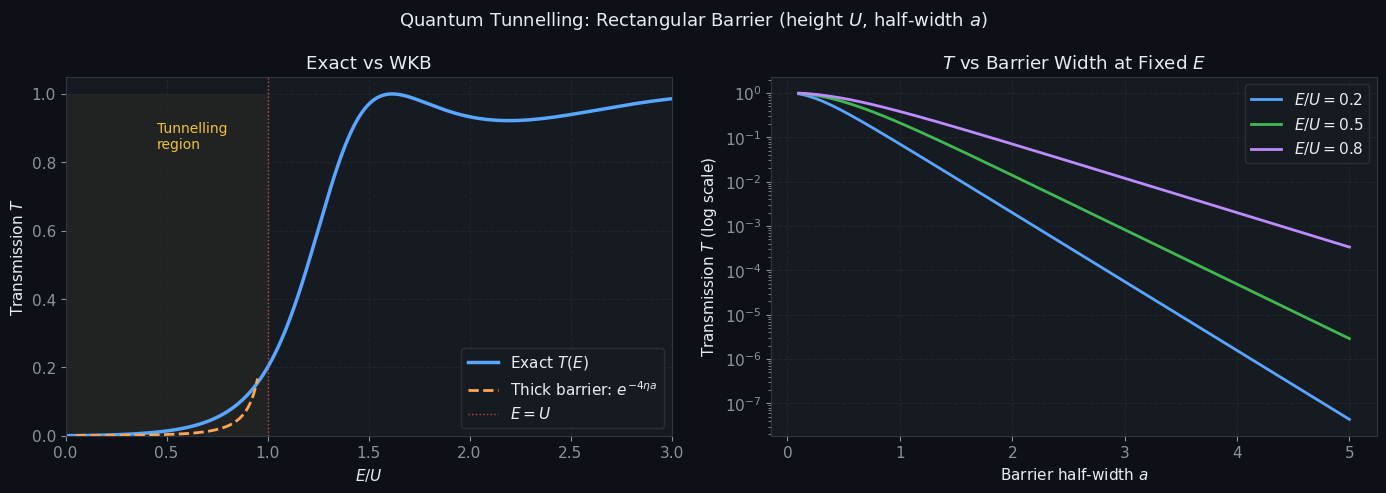

In [6]:
# ── Transmission coefficient: exact rectangular barrier ───────────────────
# ℏ = 2m = 1  →  k² = E,  η² = U-E
# Exact:  T = 1 / (1 + (U²sinh²(2ηa)) / (4E(U-E)))  for E < U
#         T = 1 / (1 + (U²sin²(2ka)) / (4E(E-U)))   for E > U

U   = 1.0   # barrier height
a   = 2.0   # half-width
E_below = np.linspace(0.001, U-0.001, 500)
E_above = np.linspace(U+0.001, 3*U, 500)
E_all   = np.concatenate([E_below, E_above])

def transmission(E, U, a):
    T = np.zeros_like(E)
    below = E < U
    # sub-barrier
    Eb = E[below]; eta = np.sqrt(U - Eb)
    sh = np.sinh(2*eta*a)
    T[below] = 1.0 / (1 + U**2 * sh**2 / (4 * Eb * (U - Eb)))
    # above-barrier
    Ea = E[~below]; k  = np.sqrt(Ea - U)
    sn = np.sin(2*k*a)
    T[~below] = 1.0 / (1 + U**2 * sn**2 / (4 * Ea * (Ea - U)))
    return T

T_exact = transmission(E_all, U, a)

# WKB approximation (thick barrier: E << U)
E_wkb = np.linspace(0.05*U, 0.95*U, 200)
T_wkb = np.exp(-4*a*np.sqrt(U - E_wkb))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Quantum Tunnelling: Rectangular Barrier (height $U$, half-width $a$)', fontsize=13)

ax = axes[0]
ax.plot(E_all/U, T_exact, color=COLORS['cyan'], lw=2.5, label='Exact $T(E)$')
ax.plot(E_wkb/U, T_wkb, color=COLORS['orange'], lw=2, ls='--',
        label=r'Thick barrier: $e^{-4\eta a}$')
ax.axvline(1.0, color=COLORS['red'], lw=1, ls=':', alpha=0.8, label='$E=U$')
ax.fill_betweenx([0, 1], 0, 1, alpha=0.05, color=COLORS['yellow'])
ax.set_xlabel('$E/U$'); ax.set_ylabel('Transmission $T$')
ax.set_title('Exact vs WKB')
ax.legend(); ax.grid(True); ax.set_xlim(0, 3); ax.set_ylim(0, 1.05)
ax.text(0.15, 0.8, 'Tunnelling\nregion', transform=ax.transAxes,
        color=COLORS['yellow'], fontsize=10)

# Barrier width dependence
ax = axes[1]
E_fix = 0.5 * U
widths = np.linspace(0.1, 5, 300)
colors_w = [COLORS['cyan'], COLORS['green'], COLORS['purple']]
for i, Efix in enumerate([0.2*U, 0.5*U, 0.8*U]):
    eta = np.sqrt(U - Efix)
    sh  = np.sinh(2*eta*widths)
    T_w = 1.0 / (1 + U**2 * sh**2 / (4*Efix*(U-Efix)))
    ax.semilogy(widths, T_w, color=colors_w[i], lw=2, label=fr'$E/U={Efix/U:.1f}$')

ax.set_xlabel('Barrier half-width $a$'); ax.set_ylabel('Transmission $T$ (log scale)')
ax.set_title('$T$ vs Barrier Width at Fixed $E$')
ax.legend(); ax.grid(True)

plt.tight_layout()
plt.savefig('qm_viz5_tunnelling.png', dpi=150, bbox_inches='tight')
plt.show()

## 6 · Hydrogen Atom Orbitals (Ch 4)
Plot radial probability densities $r^2|R_{nl}|^2$ and 2D cross-sections of $|\psi_{nlm}|^2$.

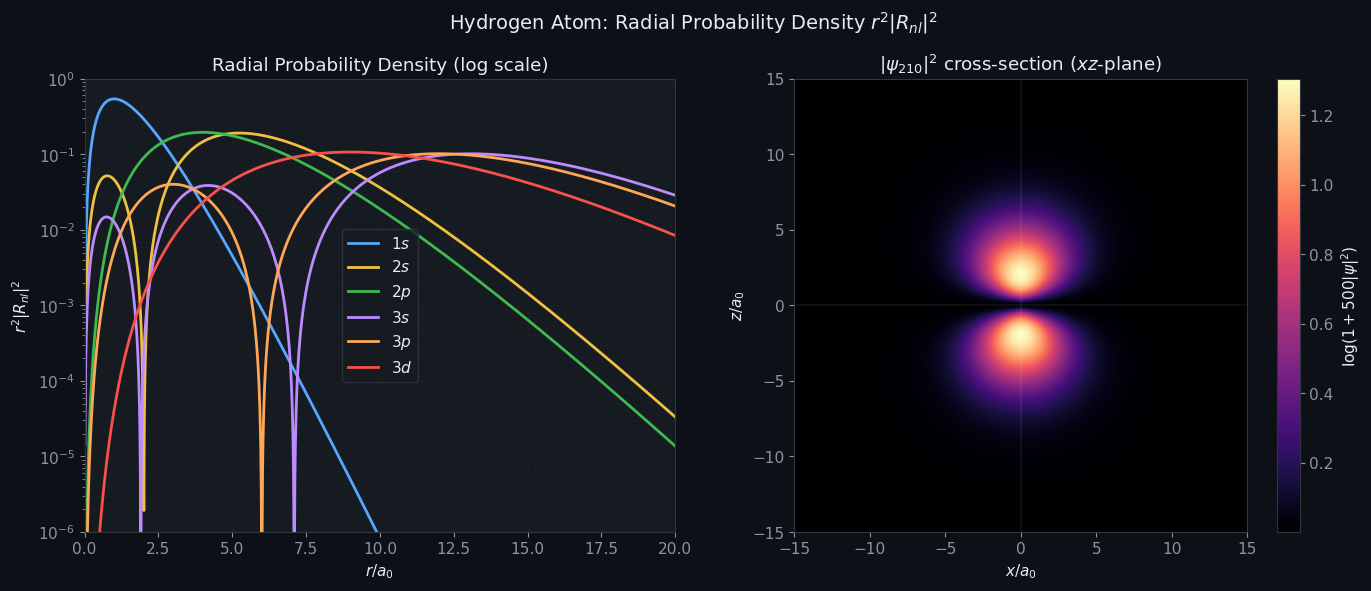

In [7]:
from scipy.special import assoc_laguerre, factorial

def hydrogen_radial(n, l, r):
    """Radial wavefunction R_nl(r) in units of Bohr radius."""
    rho  = 2*r / n
    norm = np.sqrt((2/n)**3 * factorial(n-l-1) / (2*n * factorial(n+l)))   # scipy's (modern) Laguerre convention
    L    = assoc_laguerre(rho, n-l-1, 2*l+1)
    return norm * np.exp(-rho/2) * rho**l * L

r = np.linspace(0.01, 30, 2000)
states = [(1,0,'1s'), (2,0,'2s'), (2,1,'2p'), (3,0,'3s'), (3,1,'3p'), (3,2,'3d')]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Hydrogen Atom: Radial Probability Density $r^2|R_{nl}|^2$', fontsize=14)

ax = axes[0]
state_colors = [COLORS['cyan'], COLORS['yellow'], COLORS['green'],
                COLORS['purple'], COLORS['orange'], COLORS['red']]
for (n, l, label), col in zip(states, state_colors):
    R = hydrogen_radial(n, l, r)
    ax.plot(r, r**2 * R**2, color=col, lw=2, label=f'${label}$')
ax.set_xlabel('$r/a_0$'); ax.set_ylabel(r'$r^2|R_{nl}|^2$')
ax.set_title('Radial Probability Density (log scale)')
ax.set_yscale('log')
ax.set_xlim(0, 20)
ax.set_ylim(1e-6, 1.0)      # log range captures all peaks including n=3
ax.legend(); ax.grid(True, which='both', alpha=0.4)

# 2D cross-section of |ψ_nlm|²
ax = axes[1]
grid = 200
lim  = 15
z, x2d = np.mgrid[-lim:lim:grid*1j, -lim:lim:grid*1j]
r2d  = np.sqrt(x2d**2 + z**2)
theta = np.arctan2(np.sqrt(x2d**2), z)
phi   = np.zeros_like(x2d)

# n=2, l=1, m=0 : 2p_z
R2d   = hydrogen_radial(2, 1, r2d + 1e-8)
Ylm   = sph_harm_y(1, 0, theta, phi).real   # (l, m, polar, azimuth)
psi2d = R2d * Ylm
prob2d = np.abs(psi2d)**2

im = ax.imshow(np.log1p(prob2d * 500), extent=[-lim,lim,-lim,lim],
               origin='lower', cmap='magma', aspect='equal')
plt.colorbar(im, ax=ax, label=r'$\log(1+500|\psi|^2)$')
ax.set_xlabel('$x/a_0$'); ax.set_ylabel('$z/a_0$')
ax.set_title(r'$|\psi_{210}|^2$ cross-section ($xz$-plane)')
ax.axhline(0, color='white', lw=0.3, alpha=0.3)
ax.axvline(0, color='white', lw=0.3, alpha=0.3)

plt.tight_layout()
plt.savefig('qm_viz6_hydrogen.png', dpi=150, bbox_inches='tight')
plt.show()

## 7 · Heisenberg Uncertainty Principle (Ch 3)
Show how narrowing a Gaussian in position space broadens its Fourier transform (momentum space), and plot $\Delta x \cdot \Delta p$ vs width $\sigma$.

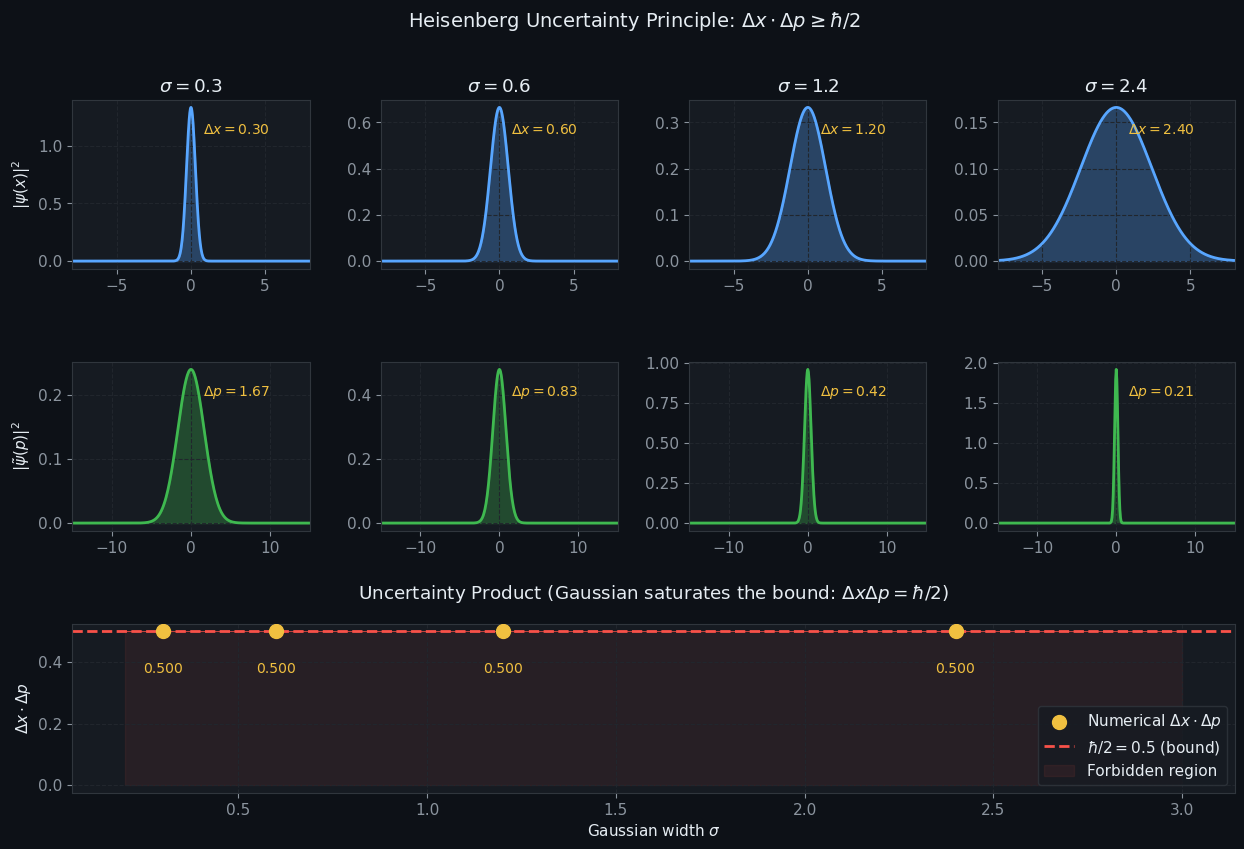

Δx · Δp products: ['0.5000', '0.5000', '0.5000', '0.5000']


In [8]:
N  = 4096
dx = 0.02
x  = (np.arange(N) - N//2) * dx
sigmas = [0.3, 0.6, 1.2, 2.4]

fig = plt.figure(figsize=(15, 9))
gs  = gridspec.GridSpec(3, len(sigmas), figure=fig, hspace=0.55, wspace=0.3)
fig.suptitle(
    r'Heisenberg Uncertainty Principle: $\Delta x \cdot \Delta p \geq \hbar/2$',
    fontsize=14)

dx_vals, dp_vals = [], []
for col, sig in enumerate(sigmas):
    psi_x = np.exp(-x**2 / (4*sig**2))
    psi_x /= np.sqrt(trapz(np.abs(psi_x)**2, x))

    # Momentum space via FFT
    psi_k_raw = fftshift(fft(psi_x)) * dx
    k_vals    = fftshift(fftfreq(N, d=dx)) * 2 * np.pi
    psi_k     = psi_k_raw / np.sqrt(trapz(np.abs(psi_k_raw)**2, k_vals) + 1e-30)

    P_x = np.abs(psi_x)**2
    P_k = np.abs(psi_k)**2

    mean_x = trapz(x * P_x, x)
    mean_x2 = trapz(x**2 * P_x, x)
    Dx = np.sqrt(mean_x2 - mean_x**2)

    mean_k = trapz(k_vals * P_k, k_vals)
    mean_k2 = trapz(k_vals**2 * P_k, k_vals)
    Dp = np.sqrt(abs(mean_k2 - mean_k**2))

    dx_vals.append(Dx); dp_vals.append(Dp)

    # Row 0: position
    ax0 = fig.add_subplot(gs[0, col])
    ax0.fill_between(x, P_x, alpha=0.3, color=COLORS['cyan'])
    ax0.plot(x, P_x, color=COLORS['cyan'], lw=2)
    ax0.set_xlim(-8, 8); ax0.set_title(fr'$\sigma={sig}$')
    if col == 0: ax0.set_ylabel(r'$|\psi(x)|^2$')
    ax0.text(0.55, 0.8, fr'$\Delta x={Dx:.2f}$', transform=ax0.transAxes,
             color=COLORS['yellow'], fontsize=10)
    ax0.grid(True)

    # Row 1: momentum
    ax1 = fig.add_subplot(gs[1, col])
    mask = (k_vals > -15) & (k_vals < 15)
    ax1.fill_between(k_vals[mask], P_k[mask], alpha=0.3, color=COLORS['green'])
    ax1.plot(k_vals[mask], P_k[mask], color=COLORS['green'], lw=2)
    ax1.set_xlim(-15, 15)
    if col == 0: ax1.set_ylabel(r'$|\tilde{\psi}(p)|^2$')
    ax1.text(0.55, 0.8, fr'$\Delta p={Dp:.2f}$', transform=ax1.transAxes,
             color=COLORS['yellow'], fontsize=10)
    ax1.grid(True)

# Row 2: Δx·Δp vs σ
ax2 = fig.add_subplot(gs[2, :])
sigma_range = np.linspace(0.2, 3, 200)
DxDp_vals = np.array(dx_vals) * np.array(dp_vals)
ax2.scatter(sigmas, DxDp_vals, color=COLORS['yellow'], s=100, zorder=5,
            label=r'Numerical $\Delta x\cdot\Delta p$')
ax2.axhline(0.5, color=COLORS['red'], lw=2, ls='--', label=r'$\hbar/2 = 0.5$ (bound)')
ax2.plot(sigma_range, 0.5*np.ones_like(sigma_range), color=COLORS['red'], lw=0.5)
ax2.fill_between(sigma_range, 0, 0.5, alpha=0.08, color=COLORS['red'], label='Forbidden region')
ax2.set_xlabel(r'Gaussian width $\sigma$')
ax2.set_ylabel(r'$\Delta x \cdot \Delta p$')
ax2.set_title(r'Uncertainty Product (Gaussian saturates the bound: $\Delta x\Delta p = \hbar/2$)',
             pad=18)
ax2.legend(loc='lower right'); ax2.grid(True)
for s, val in zip(sigmas, DxDp_vals):
    ax2.annotate(f'{val:.3f}', (s, val), textcoords='offset points',
                 xytext=(0, -22), ha='center', va='top',
                 color=COLORS['yellow'], fontsize=10)

plt.savefig('qm_viz7_uncertainty.png', dpi=150, bbox_inches='tight')
plt.show()
print('Δx · Δp products:', [f'{v:.4f}' for v in DxDp_vals])